# DLY0100 · Evaluación Parcial N°2
## Implementación y optimización de Redes Convolucionales (CNN 2D) — Dataset OUC-CGE

**Integrantes:** Lucia Salazar



## 1. Introducción y descripción del problema

El **engagement** es el grado de atención, participación e involucramiento observable de los estudiantes durante una actividad de aprendizaje. En este trabajo se clasifica el **engagement grupal** de una sala de clases a partir de **imágenes estáticas** extraídas de clips de video reales (dataset OUC-CGE), en tres clases:

| ID | Clase | Significado |
|---|---|---|
| 0 | `low` | engagement bajo |
| 1 | `mid` | engagement medio |
| 2 | `high` | engagement alto |

**Objetivo:** diseñar, entrenar y evaluar una **CNN 2D propia** (TensorFlow/Keras) que aprenda patrones visuales para clasificar una imagen en una de las tres clases. No se busca solo maximizar la accuracy, sino demostrar una metodología experimental correcta (train/validation/test), justificar decisiones de diseño e interpretar críticamente los resultados.

**Herramientas:** Python, TensorFlow/Keras (modelado y entrenamiento), `tf.data` + TFRecord (carga eficiente), scikit-learn (métricas), matplotlib/pandas (visualización y tablas), Google Colab con GPU (cómputo).

**Regla metodológica:** TRAIN entrena pesos · VALIDATION compara configuraciones y selecciona el modelo · TEST se usa **una sola vez**, al final.

In [3]:
# ===== Configuración general y reproducibilidad =====
import os, json, zipfile, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

IMG_HEIGHT = IMG_WIDTH = 128
CLASS_NAMES = ["low", "mid", "high"]
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
# ===== Ubicación del dataset =====
# Opción A (por defecto): sube el ZIP cuando lo pida Colab (o arrástralo a /content).
# Opción B: si el ZIP está en tu Google Drive, escribe su ruta en DRIVE_ZIP, p. ej.
#           DRIVE_ZIP = "/content/drive/MyDrive/OUC_CGE_DLY0100_EP2.zip"
DRIVE_ZIP = None

DATA_ROOT = Path("/content/OUC_CGE_DLY0100_EP2")

if not DATA_ROOT.exists():
    if DRIVE_ZIP:
        from google.colab import drive
        drive.mount("/content/drive")
        zip_path = Path(DRIVE_ZIP)
    else:
        zip_path = Path("/content/OUC_CGE_DLY0100_EP2.zip")
        if not zip_path.exists():
            from google.colab import files
            files.upload()          # selecciona OUC_CGE_DLY0100_EP2.zip
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("/content")

TF_ROOT, META_ROOT = DATA_ROOT / "tfrecords", DATA_ROOT / "metadata"
print("Dataset en:", DATA_ROOT, "| existe:", DATA_ROOT.exists())

Dataset en: /content/OUC_CGE_DLY0100_EP2 | existe: True


In [5]:
import glob, shutil, zipfile
from pathlib import Path

src = glob.glob("/content/OUC_CGE_DLY0100_EP2*.zip")[0]
print("Encontré:", src)
shutil.move(src, "/content/OUC_CGE_DLY0100_EP2.zip")
with zipfile.ZipFile("/content/OUC_CGE_DLY0100_EP2.zip") as z:
    z.extractall("/content")

DATA_ROOT = Path("/content/OUC_CGE_DLY0100_EP2")
TF_ROOT, META_ROOT = DATA_ROOT / "tfrecords", DATA_ROOT / "metadata"
print("Dataset en:", DATA_ROOT, "| existe:", DATA_ROOT.exists())

Encontré: /content/OUC_CGE_DLY0100_EP2 (1).zip
Dataset en: /content/OUC_CGE_DLY0100_EP2 | existe: True


**Justificación de decisiones:** se usan TFRecord y `tf.data` para leer las imágenes por lotes
sin cargar todo el dataset en memoria. Se entrena en GPU (T4) en Colab por velocidad. Se
construye una CNN propia (sin transfer learning) porque así lo exige la actividad y permite
analizar el efecto de cada componente. Se fija la semilla (SEED = 42) y se respetan los
splits entregados, definidos por clip, para que los resultados sean reproducibles y sin
fuga de información.

## 2. Descripción del dataset

El dataset contiene **12.000 imágenes RGB de 128×128 px**, provenientes de **4.000 clips** (3 imágenes por clip, tomadas al 25 %, 50 % y 75 % del clip). Los conjuntos ya vienen definidos y **no se mezclan ni redistribuyen**:

| Conjunto | Imágenes | Uso |
|---|---|---|
| Train | 9.600 | Entrenamiento de los pesos |
| Validation | 1.200 | Comparar configuraciones, ajustar hiperparámetros, seleccionar modelo |
| Test | 1.200 | Evaluación final del modelo seleccionado |

A continuación se verifican tamaños y distribución por clase usando los CSV de metadata (solo conteos; **no se inspecciona TEST visualmente ni se usa para decidir nada**).

Imágenes: 12000 | Clips: 4000 | Tamaño: [128, 128, 3]
Splits: {'train': 9600, 'val': 1200, 'test': 1200} | Clases: {'low': 0, 'mid': 1, 'high': 2}


,train,val,test
class_name,,,
low,3201,402,405
mid,3201,399,390
high,3198,399,405
TOTAL,9600,1200,1200


,train,val,test
proporción por split,,,
low,0.333,0.335,0.338
mid,0.333,0.332,0.325
high,0.333,0.332,0.338


Clips compartidos train∩val: 0 | train∩test: 0 | val∩test: 0


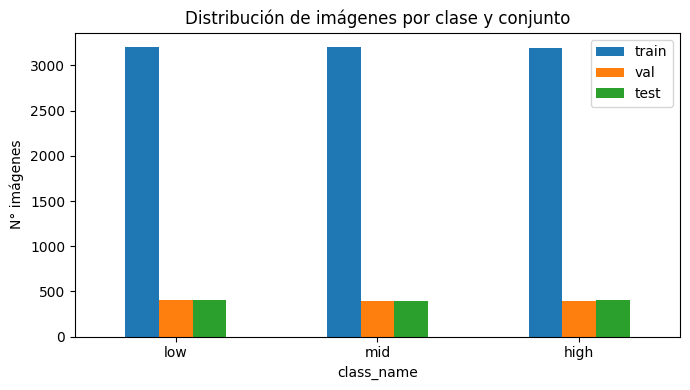

In [3]:
meta = json.loads((META_ROOT / "tfrecords_metadata.json").read_text(encoding="utf-8"))
print("Imágenes:", meta["n_images"], "| Clips:", meta["n_clips"], "| Tamaño:", meta["image_size"])
print("Splits:", meta["split_counts"], "| Clases:", meta["class_to_id"])

dfs = {s: pd.read_csv(META_ROOT / f"{s}_frames.csv") for s in ["train", "val", "test"]}

# Distribución por clase y split
dist = pd.DataFrame({s: d["class_name"].value_counts().reindex(CLASS_NAMES) for s, d in dfs.items()})
dist.loc["TOTAL"] = dist.sum()
display(dist)
display((dist.drop("TOTAL") / dist.drop("TOTAL").sum()).round(3).rename_axis("proporción por split"))

# Verificación: ningún clip aparece en más de un split (sin fuga de información)
clips = {s: set(d["source_video_relpath"]) for s, d in dfs.items()}
print("Clips compartidos train∩val:", len(clips["train"] & clips["val"]),
      "| train∩test:", len(clips["train"] & clips["test"]),
      "| val∩test:", len(clips["val"] & clips["test"]))

dist.drop("TOTAL").plot(kind="bar", figsize=(7, 4), rot=0, title="Distribución de imágenes por clase y conjunto")
plt.ylabel("N° imágenes"); plt.tight_layout(); plt.show()

**Observaciones del dataset:** las tres clases están balanceadas en los tres conjuntos
(≈ 33% cada una; por ejemplo, en train 3.201 low, 3.201 mid y 3.198 high). Por eso la
accuracy es una métrica razonable y no se requieren pesos de clase ni técnicas de
rebalanceo. Además, no hay clips compartidos entre train, validation y test (0 en las
tres combinaciones), porque el split se hizo por clip. Esto evita fuga de información,
ya que las 3 imágenes de un mismo clip nunca quedan repartidas entre conjuntos, y
asegura que el desempeño en validation y test refleje generalización a clips nuevos.

## 3. Carga de TFRecords

Se usa `tf.data`: lectura de los TFRecord, decodificación JPEG, `batch` y `prefetch`. El **shuffle** se aplica solo en entrenamiento. El **escalado a [0,1]** y la **data augmentation** se hacen *dentro del modelo* (capas Keras), de modo que se activan únicamente en entrenamiento y la evaluación es determinista.



In [7]:
FEATURE_SPEC = {
    "image_raw": tf.io.FixedLenFeature([], tf.string),
    "label": tf.io.FixedLenFeature([], tf.int64),
    "clip_key": tf.io.FixedLenFeature([], tf.string),
    "image_relpath": tf.io.FixedLenFeature([], tf.string),
}

def parse_record(serialized):
    """Decodifica un registro TFRecord -> (imagen float32 [0,255] 128x128x3, label int32)."""
    ex = tf.io.parse_single_example(serialized, FEATURE_SPEC)
    image = tf.io.decode_jpeg(ex["image_raw"], channels=3)
    image = tf.ensure_shape(image, [IMG_HEIGHT, IMG_WIDTH, 3])
    return tf.cast(image, tf.float32), tf.cast(ex["label"], tf.int32)

TRAIN_FILES = [str(TF_ROOT / f"train_{i:02d}.tfrecord") for i in range(4)]
VAL_FILES   = [str(TF_ROOT / "val.tfrecord")]
TEST_FILES  = [str(TF_ROOT / "test.tfrecord")]   # NO usar hasta la sección 7

def make_dataset(files, batch_size=64, training=False):
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=AUTOTUNE if training else 1)
    if training:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(parse_record, num_parallel_calls=AUTOTUNE, deterministic=not training)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

def get_labels(files):
    spec = {"label": tf.io.FixedLenFeature([], tf.int64)}
    ds = tf.data.TFRecordDataset(files).map(lambda s: tf.io.parse_single_example(s, spec)["label"])
    return np.array(list(ds.as_numpy_iterator()))

# Verificación de dimensiones, clases y cantidad de ejemplos (train y val)
for name, files in [("train", TRAIN_FILES), ("val", VAL_FILES)]:
    y = get_labels(files)
    print(f"{name:5s}: {len(y)} ejemplos | por clase:", dict(zip(CLASS_NAMES, np.bincount(y, minlength=3))))

xb, yb = next(iter(make_dataset(TRAIN_FILES, 64, True)))
print("Batch:", xb.shape, xb.dtype, "| rango píxeles:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)), "| labels:", yb.shape)

train: 9600 ejemplos | por clase: {'low': np.int64(3201), 'mid': np.int64(3201), 'high': np.int64(3198)}
val  : 1200 ejemplos | por clase: {'low': np.int64(402), 'mid': np.int64(399), 'high': np.int64(399)}
Batch: (64, 128, 128, 3) <dtype: 'float32'> | rango píxeles: 0.0 - 255.0 | labels: (64,)


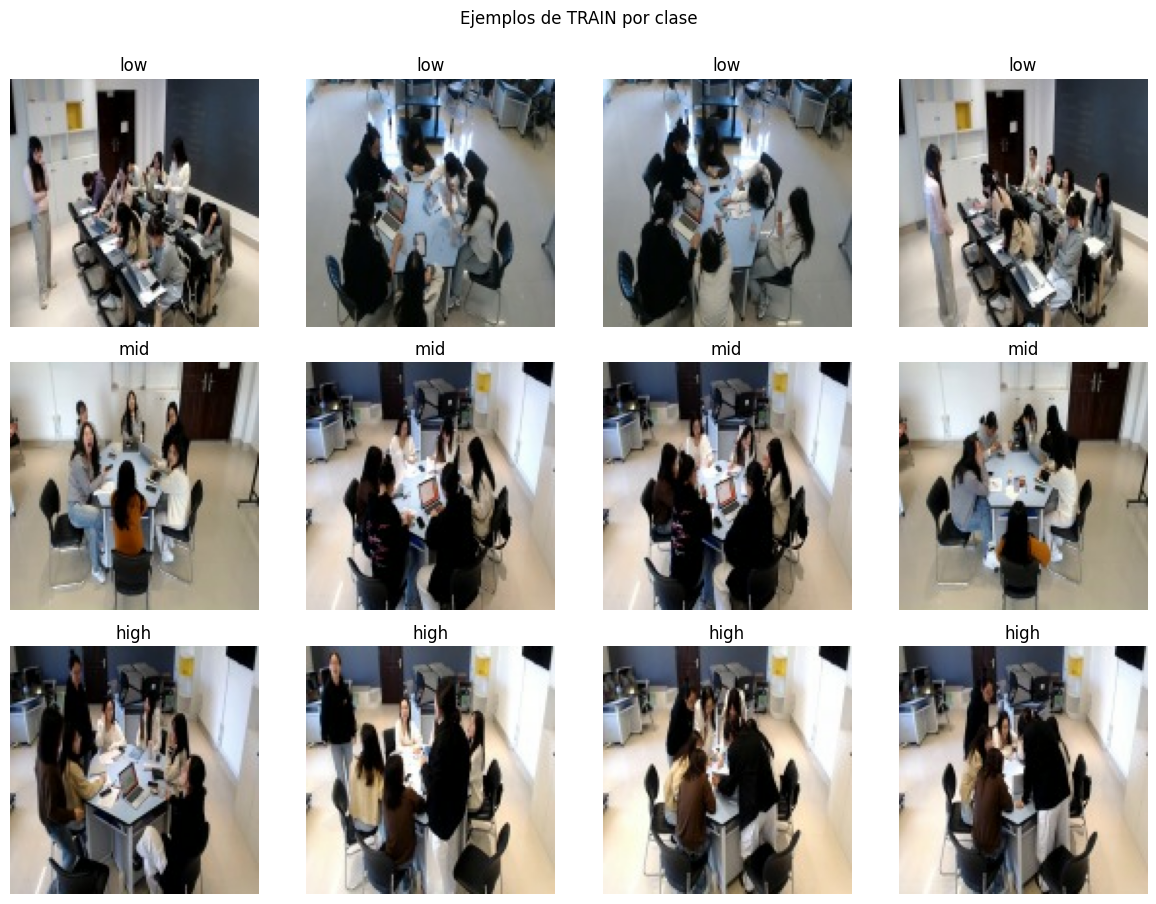

In [8]:
# Ejemplos representativos (solo TRAIN): 4 por clase
imgs_by_class = {c: [] for c in range(3)}
for x, y in make_dataset(TRAIN_FILES, 256, True):   # sin .take(4): recorre hasta tener las 12
    for img, lab in zip(x.numpy(), y.numpy()):
        if len(imgs_by_class[lab]) < 4:
            imgs_by_class[lab].append(img.astype("uint8"))
    if all(len(v) == 4 for v in imgs_by_class.values()):
        break

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for c in range(3):
    for j in range(4):
        axes[c, j].imshow(imgs_by_class[c][j]); axes[c, j].axis("off")
        axes[c, j].set_title(CLASS_NAMES[c])
plt.suptitle("Ejemplos de TRAIN por clase", y=1.0); plt.tight_layout(); plt.show()

**Observación visual de los ejemplos:** las tres clases comparten la misma sala, cámara
e iluminación, por lo que las diferencias no son evidentes. En `high` los estudiantes
suelen verse más agrupados e inclinados hacia el centro de la mesa, mientras que en `low`
aparecen más separados o con un integrante de pie. Las diferencias pueden ser sutiles y la
etiqueta proviene del comportamiento en el clip completo, no solo de este frame, por lo
que un frame aislado puede no contener evidencia suficiente.

## 4. Arquitectura CNN propuesta

Se implementa una función `build_cnn(...)` parametrizable para poder comparar configuraciones de forma sistemática y reproducible.

**Diseño base (bloques Conv → [BN] → ReLU → MaxPool):**

| Componente | Decisión | Justificación |
|---|---|---|
| `Rescaling(1/255)` | normalizar píxeles a [0,1] | estabiliza el entrenamiento y la escala de gradientes |
| `Conv2D` 3×3, `padding="same"` | kernels pequeños apilados | capturan patrones locales (posturas, bordes, texturas) con pocos parámetros y campo receptivo creciente |
| Filtros 32→64→128(→256) | duplicar filtros al reducir resolución | más canales para características más abstractas mientras baja la resolución espacial |
| `ReLU` | activación | no saturante, entrenamiento rápido, estándar en CNN |
| `MaxPooling2D` 2×2 | submuestreo | reduce costo e introduce invarianza a pequeñas traslaciones |
| `BatchNormalization` (exp.) | normalizar activaciones | estabiliza y acelera el entrenamiento, permite LR mayores, efecto regularizador leve |
| `Dropout` (exp.) | apagar neuronas al azar | reduce overfitting (dataset de ~9.600 imágenes, modelo con muchos parámetros) |
| `Flatten`/`GlobalAveragePooling2D` | del mapa de características al clasificador | GAP reduce drásticamente parámetros densos frente a Flatten |
| `Dense(3, softmax)` | salida | distribución de probabilidad P(low), P(mid), P(high) |
| Data augmentation (exp.) | flip horizontal, rotación, zoom, traslación, contraste | simula variaciones de cámara/iluminación y mejora generalización |
| Optimizador Adam + `ReduceLROnPlateau` + `EarlyStopping` | | convergencia robusta; EarlyStopping (sobre *val_loss*) decide las épocas usando solo validation |

In [9]:
def augmentation_block():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.10),
    ], name="augmentation")

def build_cnn(filters=(32, 64, 128), kernel_size=3, convs_per_block=1,
              use_bn=False, dropout_conv=0.0, dense_units=128, dropout_dense=0.0,
              l2=0.0, pooling="flatten", augment=False, name="cnn"):
    """CNN 2D parametrizable. Devuelve un modelo Keras SIN compilar."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    inputs = keras.Input((IMG_HEIGHT, IMG_WIDTH, 3))
    x = inputs
    if augment:
        x = augmentation_block()(x)          # solo activa en entrenamiento
    x = layers.Rescaling(1.0 / 255)(x)

    for f in filters:
        for _ in range(convs_per_block):
            x = layers.Conv2D(f, kernel_size, padding="same", use_bias=not use_bn, kernel_regularizer=reg)(x)
            if use_bn:
                x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
        if dropout_conv > 0:
            x = layers.Dropout(dropout_conv)(x)

    x = layers.GlobalAveragePooling2D()(x) if pooling == "gap" else layers.Flatten()(x)
    if dense_units:
        x = layers.Dense(dense_units, activation="relu", kernel_regularizer=reg)(x)
        if dropout_dense > 0:
            x = layers.Dropout(dropout_dense)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

# Vista previa de la arquitectura base
build_cnn(name="preview_baseline").summary()

Model: "preview_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

**Observación del summary:** el modelo base tiene 4.288.067 parámetros, de los cuales
4.194.432 (≈98%) están en la primera capa densa, porque `Flatten` entrega un vector de
32.768 valores. Las tres capas convolucionales suman solo ≈93 mil parámetros. Esto hace
prever sobreajuste en el modelo base y motiva el uso de regularización (BatchNorm,
Dropout), augmentation y GlobalAveragePooling en los experimentos siguientes.

## 5. Experimentos realizados

Se define una función `run_experiment` que entrena con **TRAIN**, monitorea **VALIDATION** (EarlyStopping sobre `val_loss` con `restore_best_weights=True`, y `ReduceLROnPlateau`) y guarda historia, modelo y métricas de validación. **Nunca se toca TEST.**

Plan experimental (cada experimento cambia algo concreto respecto del anterior, para poder atribuir el efecto):

| Exp. | Idea | Hipótesis |
|---|---|---|
| 1 | CNN base (3 bloques conv, sin regularización) | referencia; probablemente sobreajusta |
| 2 | + BatchNorm + Dropout | reduce la brecha train/val y estabiliza |
| 3 | + Data augmentation | mejora generalización |
| 4 | Red más profunda (4 bloques, 2 conv/bloque, GAP), LR y batch distintos | más capacidad con menos parámetros densos |

> Puedes (y es recomendable) agregar o modificar experimentos según lo que observes. **Mínimo exigido: 3.**

In [10]:
RESULTS, HISTORIES, MODELS = [], {}, {}

def run_experiment(exp_id, description, build_kwargs, batch_size=64, lr=1e-3, epochs=40, patience=8):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)                      # misma semilla para todos
    train_ds = make_dataset(TRAIN_FILES, batch_size, training=True)
    val_ds   = make_dataset(VAL_FILES,   batch_size, training=False)

    model = build_cnn(name=f"exp{exp_id}", **build_kwargs)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)]

    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=2)
    elapsed = time.time() - t0

    # Con restore_best_weights, esto mide la MEJOR época según val_loss
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    h = hist.history
    RESULTS.append({
        "Exp.": exp_id, "Arquitectura / cambio realizado": description,
        "Batch": batch_size, "Learning rate": lr,
        "Épocas (ejecutadas)": len(h["loss"]), "Mejor época": int(np.argmin(h["val_loss"])) + 1,
        "Parámetros": model.count_params(),
        "Val. Accuracy": round(float(val_acc), 4), "Val. Loss": round(float(val_loss), 4),
        "Train Acc (mejor ép.)": round(float(h["accuracy"][int(np.argmin(h["val_loss"]))]), 4),
        "Tiempo (s)": round(elapsed),
    })
    HISTORIES[exp_id], MODELS[exp_id] = h, model
    return model, h

def plot_history(h, title):
    best = int(np.argmin(h["val_loss"]))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["accuracy"], label="accuracy (train)"); ax[0].plot(h["val_accuracy"], label="val_accuracy")
    ax[0].axvline(best, ls="--", c="gray", label="mejor época"); ax[0].set_title("Accuracy"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(h["loss"], label="loss (train)"); ax[1].plot(h["val_loss"], label="val_loss")
    ax[1].axvline(best, ls="--", c="gray", label="mejor época"); ax[1].set_title("Loss"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.suptitle(title); plt.tight_layout(); plt.show()

### Experimento 1 — CNN base (sin regularización)

Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


150/150 - 17s - 113ms/step - accuracy: 0.8192 - loss: 0.4512 - val_accuracy: 0.8950 - val_loss: 0.2735 - learning_rate: 0.0010
Epoch 2/40
150/150 - 6s - 39ms/step - accuracy: 0.9666 - loss: 0.0990 - val_accuracy: 0.9633 - val_loss: 0.1020 - learning_rate: 0.0010
Epoch 3/40
150/150 - 6s - 39ms/step - accuracy: 0.9894 - loss: 0.0345 - val_accuracy: 0.9742 - val_loss: 0.0746 - learning_rate: 0.0010
Epoch 4/40
150/150 - 6s - 40ms/step - accuracy: 0.9973 - loss: 0.0092 - val_accuracy: 0.9700 - val_loss: 0.0917 - learning_rate: 0.0010
Epoch 5/40
150/150 - 6s - 40ms/step - accuracy: 0.9972 - loss: 0.0087 - val_accuracy: 0.9875 - val_loss: 0.0312 - learning_rate: 0.0010
Epoch 6/40
150/150 - 6s - 40ms/step - accuracy: 0.9997 - loss: 0.0018 - val_accuracy: 0.9842 - val_loss: 0.0618 - learning_rate: 0.0010
Epoch 7/40
150/150 - 10s - 68ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9850 - val_loss: 0.0472 - learning_rate: 0.0010
Epoch 8/40

Epoch 8: ReduceLROnPlateau reducing learning

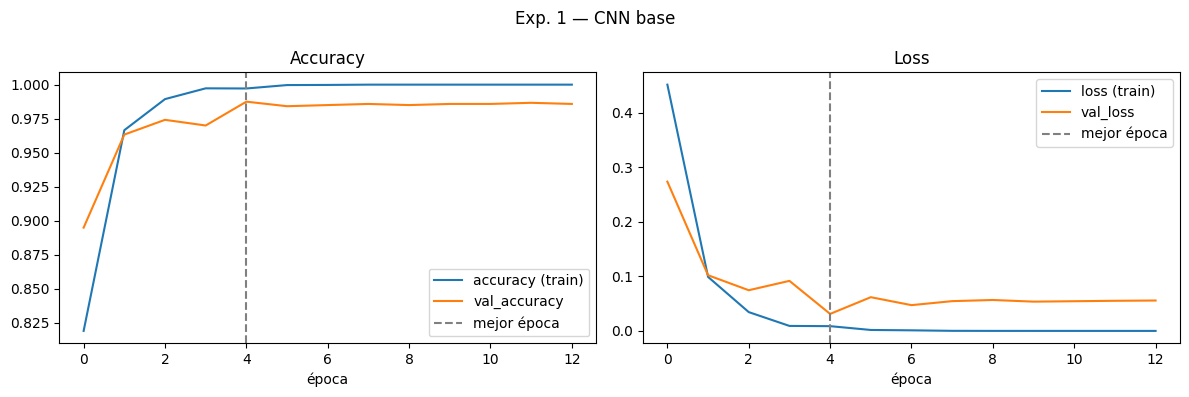

In [11]:
run_experiment(1, "Base: 3 bloques Conv(32-64-128)+MaxPool, Flatten, Dense128. Sin BN/Dropout/Aug.",
               dict(filters=(32, 64, 128), dense_units=128),
               batch_size=64, lr=1e-3)
plot_history(HISTORIES[1], "Exp. 1 — CNN base")

**Interpretación Exp. 1:** el modelo base alcanza accuracy de 1.0 en train desde la época 5
y ≈0,985 en validation. La val_loss alcanza su mínimo (≈0,03) en la época 5 y luego sube
hasta ≈0,055, mientras la loss de train tiende a 0: el modelo comienza a sobreajustar desde
esa época, aunque la accuracy de validation no cae. Hubo unas 5 épocas útiles; EarlyStopping
detuvo el entrenamiento en la 13 y restauró los mejores pesos. El resultado es muy
alto para un problema de diferencias sutiles, lo que sugiere que el modelo podría usar atajos
(sala, encuadre, grupo), algo a verificar en los demás experimentos.

### Experimento 2 — + BatchNormalization y Dropout

Epoch 1/40
150/150 - 17s - 116ms/step - accuracy: 0.5876 - loss: 2.1979 - val_accuracy: 0.3350 - val_loss: 2.6270 - learning_rate: 0.0010
Epoch 2/40
150/150 - 7s - 46ms/step - accuracy: 0.5829 - loss: 0.8995 - val_accuracy: 0.3350 - val_loss: 3.0018 - learning_rate: 0.0010
Epoch 3/40
150/150 - 7s - 47ms/step - accuracy: 0.5195 - loss: 0.9409 - val_accuracy: 0.3350 - val_loss: 2.0077 - learning_rate: 0.0010
Epoch 4/40
150/150 - 7s - 47ms/step - accuracy: 0.5220 - loss: 0.9221 - val_accuracy: 0.5883 - val_loss: 0.8456 - learning_rate: 0.0010
Epoch 5/40
150/150 - 7s - 47ms/step - accuracy: 0.5334 - loss: 0.9127 - val_accuracy: 0.6442 - val_loss: 0.7989 - learning_rate: 0.0010
Epoch 6/40
150/150 - 7s - 47ms/step - accuracy: 0.5406 - loss: 0.9009 - val_accuracy: 0.6300 - val_loss: 0.7704 - learning_rate: 0.0010
Epoch 7/40
150/150 - 7s - 47ms/step - accuracy: 0.5328 - loss: 0.8968 - val_accuracy: 0.6608 - val_loss: 0.7433 - learning_rate: 0.0010
Epoch 8/40
150/150 - 7s - 47ms/step - accuracy

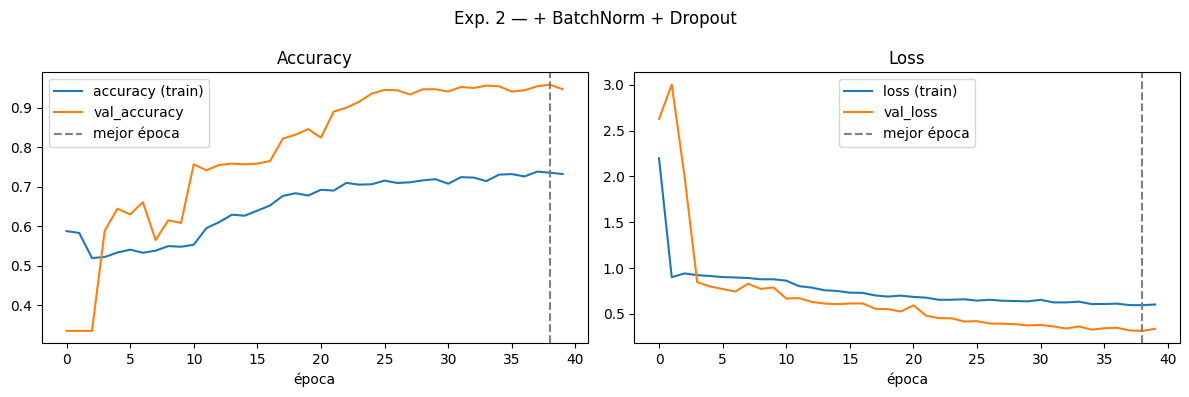

In [12]:
run_experiment(2, "Exp1 + BatchNorm en cada Conv + Dropout(0.25) tras cada bloque + Dropout(0.5) en Dense.",
               dict(filters=(32, 64, 128), dense_units=128, use_bn=True, dropout_conv=0.25, dropout_dense=0.5),
               batch_size=64, lr=1e-3)
plot_history(HISTORIES[2], "Exp. 2 — + BatchNorm + Dropout")

**Interpretación Exp. 2:** agregar BatchNorm y Dropout eliminó el sobreajuste visto en el Exp. 1:
ya no hay brecha train→val, y la accuracy de train (≈0,73) quedó incluso por debajo de la de
validation (≈0,95), porque el Dropout está activo solo durante el entrenamiento. Sin embargo, el
rendimiento empeoró respecto del Exp. 1 (val_accuracy ≈0,96 vs ≈0,99; val_loss ≈0,31 vs ≈0,03).
El entrenamiento fue más lento y las curvas seguían mejorando al llegar al máximo de 40 épocas, lo
que indica subajuste por regularización excesiva. Además, las primeras épocas fueron inestables
(val_accuracy en 0,33 hasta la época ~3), contrario a lo esperado de BatchNorm.

### Experimento 3 — + Data augmentation

Epoch 1/60
150/150 - 23s - 155ms/step - accuracy: 0.5803 - loss: 3.1017 - val_accuracy: 0.3350 - val_loss: 1.2171 - learning_rate: 0.0010
Epoch 2/60
150/150 - 13s - 89ms/step - accuracy: 0.5248 - loss: 0.9712 - val_accuracy: 0.4750 - val_loss: 0.9488 - learning_rate: 0.0010
Epoch 3/60
150/150 - 14s - 90ms/step - accuracy: 0.4871 - loss: 0.9990 - val_accuracy: 0.5600 - val_loss: 0.9020 - learning_rate: 0.0010
Epoch 4/60
150/150 - 13s - 89ms/step - accuracy: 0.4891 - loss: 0.9919 - val_accuracy: 0.6275 - val_loss: 0.9140 - learning_rate: 0.0010
Epoch 5/60
150/150 - 13s - 89ms/step - accuracy: 0.4803 - loss: 0.9962 - val_accuracy: 0.6075 - val_loss: 0.9282 - learning_rate: 0.0010
Epoch 6/60

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
150/150 - 21s - 137ms/step - accuracy: 0.4769 - loss: 0.9941 - val_accuracy: 0.6233 - val_loss: 0.9052 - learning_rate: 0.0010
Epoch 7/60
150/150 - 14s - 93ms/step - accuracy: 0.4744 - loss: 1.0001 - val_accuracy: 0.6317 - val

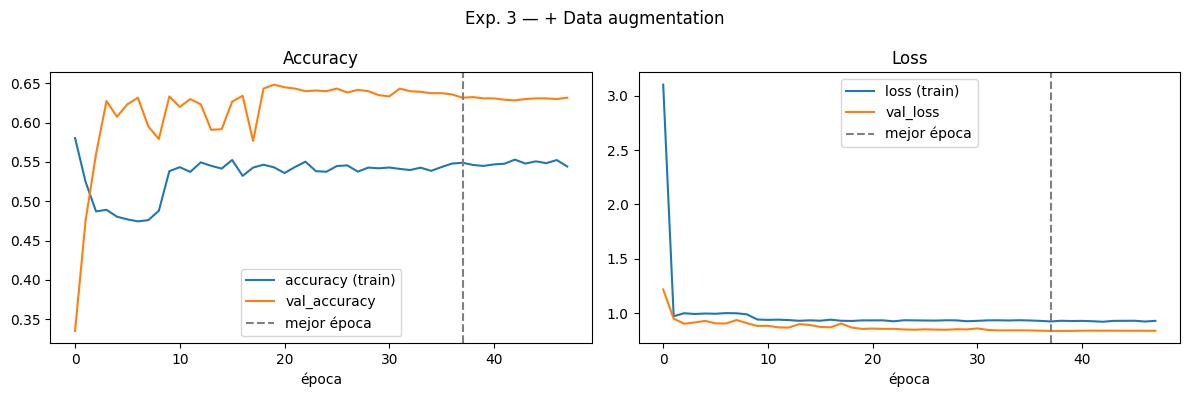

In [13]:
run_experiment(3, "Exp2 + Data augmentation (flip horiz., rot. 5%, zoom 10%, traslación 5%, contraste 10%).",
               dict(filters=(32, 64, 128), dense_units=128, use_bn=True, dropout_conv=0.25, dropout_dense=0.5, augment=True),
               batch_size=64, lr=1e-3, epochs=60, patience=10)
plot_history(HISTORIES[3], "Exp. 3 — + Data augmentation")

**Interpretación Exp. 3:** agregar data augmentation (flip, rotación ±18°, zoom, traslación y contraste) sobre el Exp. 2 redujo aún más el sobreajuste: la val_loss ya no sube y train (≈0,55) queda bajo validation (≈0,63), porque la augmentation y el Dropout solo actúan en entrenamiento. Sin embargo, el rendimiento empeoró mucho (val_accuracy≈0,63 vs ≈0,96; val_loss ≈0,84 vs ≈0,31), y la train loss (≈0,93) quedó cerca de ln(3) ≈ 1,10, el valor de adivinar entre 3 clases. No tardó más en converger, sino que se estancó en una meseta peor, y el learning rate bajó hasta 1e-6. El flip tiene sentido en un aula, pero la rotación de ±18° es poco realista con una cámara fija, y el zoom y la traslación pueden recortar personas. Sin embargo, como el Exp. 4 mantiene la misma augmentation y alcanza ≈0,95 de val_accuracy, es poco probable que las transformaciones por sí solas destruyan la información relevante; el mal resultado del Exp. 3 parece deberse más a la combinación de arquitectura (Flatten con capa densa grande), regularización y learning rate, aunque sigue siendo una hipótesis que se podría comprobar con una ablación.

### Experimento 4 — Arquitectura más profunda, GAP, otro learning rate y batch size

Epoch 1/60
300/300 - 40s - 133ms/step - accuracy: 0.6405 - loss: 0.7721 - val_accuracy: 0.4083 - val_loss: 1.4463 - learning_rate: 5.0000e-04
Epoch 2/60
300/300 - 33s - 109ms/step - accuracy: 0.6699 - loss: 0.7535 - val_accuracy: 0.6308 - val_loss: 0.8641 - learning_rate: 5.0000e-04
Epoch 3/60
300/300 - 32s - 108ms/step - accuracy: 0.7128 - loss: 0.6809 - val_accuracy: 0.5408 - val_loss: 1.4137 - learning_rate: 5.0000e-04
Epoch 4/60
300/300 - 33s - 109ms/step - accuracy: 0.7248 - loss: 0.6517 - val_accuracy: 0.5575 - val_loss: 1.3365 - learning_rate: 5.0000e-04
Epoch 5/60

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
300/300 - 33s - 109ms/step - accuracy: 0.7437 - loss: 0.6229 - val_accuracy: 0.3775 - val_loss: 2.4048 - learning_rate: 5.0000e-04
Epoch 6/60
300/300 - 33s - 109ms/step - accuracy: 0.7740 - loss: 0.5772 - val_accuracy: 0.5733 - val_loss: 0.9496 - learning_rate: 2.5000e-04
Epoch 7/60
300/300 - 33s - 109ms/step - accuracy: 0.7954 - loss: 0.5237

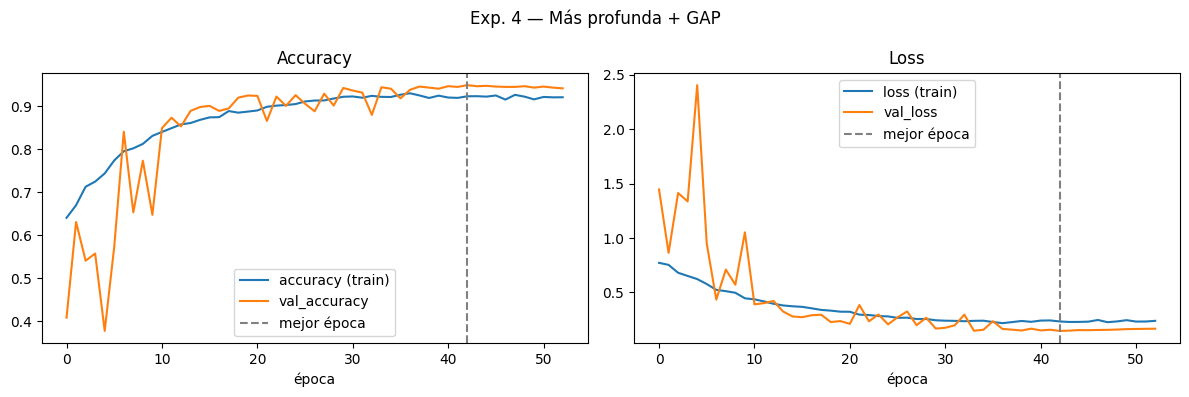

In [14]:
run_experiment(4, "4 bloques Conv(32-64-128-256), 2 Conv/bloque, BN, Dropout(0.3), GlobalAvgPool, Dense64, Aug. LR menor, batch 32.",
               dict(filters=(32, 64, 128, 256), convs_per_block=2, dense_units=64, use_bn=True,
                    dropout_conv=0.3, dropout_dense=0.5, pooling="gap", augment=True),
               batch_size=32, lr=5e-4, epochs=60, patience=10)
plot_history(HISTORIES[4], "Exp. 4 — Más profunda + GAP")

**Interpretación Exp. 4:** la red más profunda (4 bloques, 2 conv por bloque, GAP y Dense 64) recuperó el rendimiento que se perdió en el Exp. 3 manteniendo la misma augmentation: val_accuracy ≈0,94 y val_loss ≈0,17 (vs ≈0,95 y ≈0,15), con train ≈0,92 y sin sobreajuste (train queda bajo validation por el Dropout y la augmentation). Tiene ≈1,19 M de parámetros frente a ≈4,29 M de los experimentos anteriores, porque GAP elimina la gran capa densa posterior al Flatten y el peso pasa a las capas convolucionales. El LR menor (5e-4) y el batch 32 (el doble de actualizaciones por época) dejaron un entrenamiento más progresivo, aunque la validation fue muy inestable durante las primeras ~10 épocas (val_loss hasta ≈2,4). Como se cambiaron varios factores a la vez, no se puede aislar el efecto de cada uno. Aun así, no superó al Exp. 1 (≈0,985 y ≈0,03)” → “(≈0,99 y ≈0,03), aunque su curva es mucho más sana.

### Tabla comparativa de experimentos (solo VALIDATION)

,Exp.,Arquitectura / cambio realizado,Batch,Learning rate,Épocas (ejecutadas),Mejor época,Parámetros,Val. Accuracy,Val. Loss,Train Acc (mejor ép.),Tiempo (s)
0,1,"Base: 3 bloques Conv(32-64-128)+MaxPool, Flatten, Dense128. Sin BN/Dropout/Aug.",64,0.0010,13,5,4288067,0.9875,0.0312,0.9972,101
1,2,Exp1 + BatchNorm en cada Conv + Dropout(0.25) tras cada bloque + Dropout(0.5) en Dense.,64,0.0010,40,39,4288739,0.9583,0.3132,0.7354,316
2,3,"Exp2 + Data augmentation (flip horiz., rot. 5%, zoom 10%, traslación 5%, contraste 10%).",64,0.0010,48,38,4288739,0.6317,0.8363,0.5490,657
3,4,"4 bloques Conv(32-64-128-256), 2 Conv/bloque, BN, Dropout(0.3), GlobalAvgPool, Dense64, Aug. LR menor, batch 32.",32,0.0005,53,43,1191779,0.9492,0.1464,0.9232,1770


,Exp.,Arquitectura / cambio realizado,Batch,Learning rate,Épocas (ejecutadas),Val. Accuracy,Val. Loss
0,1,"Base: 3 bloques Conv(32-64-128)+MaxPool, Flatten, Dense128. Sin BN/Dropout/Aug.",64,0.0010,13,0.9875,0.0312
1,2,Exp1 + BatchNorm en cada Conv + Dropout(0.25) tras cada bloque + Dropout(0.5) en Dense.,64,0.0010,40,0.9583,0.3132
2,3,"Exp2 + Data augmentation (flip horiz., rot. 5%, zoom 10%, traslación 5%, contraste 10%).",64,0.0010,48,0.6317,0.8363
3,4,"4 bloques Conv(32-64-128-256), 2 Conv/bloque, BN, Dropout(0.3), GlobalAvgPool, Dense64, Aug. LR menor, batch 32.",32,0.0005,53,0.9492,0.1464


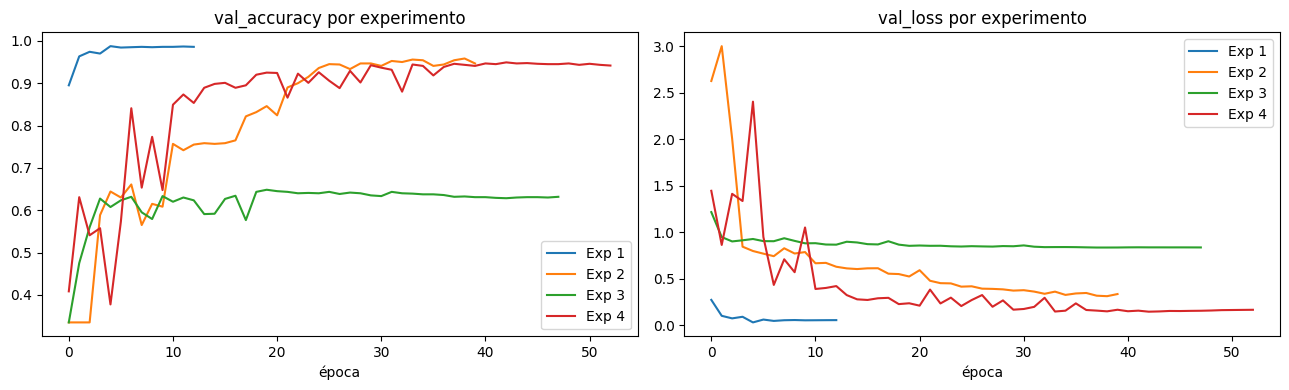

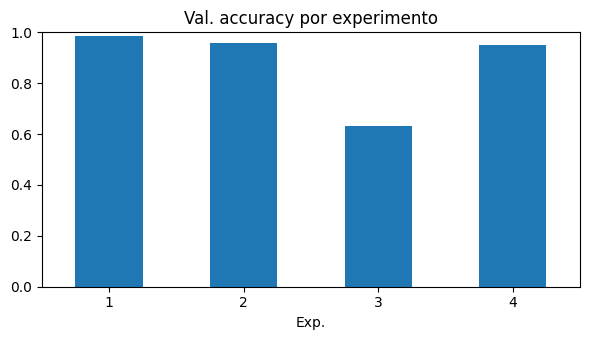

In [15]:
results_df = pd.DataFrame(RESULTS)
pd.set_option("display.max_colwidth", 120)
display(results_df)

# Tabla en el formato pedido por la pauta
display(results_df[["Exp.", "Arquitectura / cambio realizado", "Batch", "Learning rate",
                    "Épocas (ejecutadas)", "Val. Accuracy", "Val. Loss"]])

# Comparación de curvas de validación
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, h in HISTORIES.items():
    ax[0].plot(h["val_accuracy"], label=f"Exp {k}"); ax[1].plot(h["val_loss"], label=f"Exp {k}")
ax[0].set_title("val_accuracy por experimento"); ax[1].set_title("val_loss por experimento")
for a in ax: a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

results_df.set_index("Exp.")[["Val. Accuracy"]].plot(kind="bar", rot=0, legend=False, figsize=(6, 3.5), title="Val. accuracy por experimento")
plt.ylim(0, 1); plt.tight_layout(); plt.show()

## 6. Selección del modelo final

La selección se hace **exclusivamente con resultados de VALIDATION** (criterio principal: mayor `val_accuracy`; desempate: menor `val_loss`; también se considera la brecha train–val como indicador de generalización).

In [16]:
ranking = results_df.sort_values(["Val. Accuracy", "Val. Loss"], ascending=[False, True]).reset_index(drop=True)
ranking["Brecha train-val"] = (ranking["Train Acc (mejor ép.)"] - ranking["Val. Accuracy"]).round(4)
display(ranking[["Exp.", "Val. Accuracy", "Val. Loss", "Train Acc (mejor ép.)", "Brecha train-val", "Parámetros", "Mejor época"]])

FINAL_EXP = int(ranking.loc[0, "Exp."])     # <-- puedes fijarlo a mano (p. ej. FINAL_EXP = 3) si lo justificas abajo
print("Modelo seleccionado: Experimento", FINAL_EXP)
final_model = MODELS[FINAL_EXP]

,Exp.,Val. Accuracy,Val. Loss,Train Acc (mejor ép.),Brecha train-val,Parámetros,Mejor época
0,1,0.9875,0.0312,0.9972,0.0097,4288067,5
1,2,0.9583,0.3132,0.7354,-0.2229,4288739,39
2,4,0.9492,0.1464,0.9232,-0.0260,1191779,43
3,3,0.6317,0.8363,0.5490,-0.0827,4288739,38


Modelo seleccionado: Experimento 1


**Justificación técnica de la selección:**

- El **Experimento 1** obtuvo la mayor `val_accuracy` (0.9875) y la menor `val_loss` (0.0312).
- Su brecha train–val es 0.0097, es decir, hay muy poco overfitting. Los Exp. 2, 3 y 4 tienen brecha negativa porque su accuracy de entrenamiento se mide con Dropout y/o augmentation activos, así que no son comparables directamente.
- Las curvas del Exp. 1 son estables: la val_accuracy sube rápido y se mantiene cerca de 0.98–0.99, y la mejor época fue la 5. El EarlyStopping detuvo el entrenamiento en la época 13. Las curvas del Exp. 2 y 4 oscilan bastante más y necesitan 40–50 épocas para llegar a niveles menores.
- Frente al resto: el Exp. 2 (BN + Dropout) quedó 3 puntos bajo (0.9583) y con val_loss 10 veces mayor (0.3132). El Exp. 3 (augmentation) cayó a 0.6317, por lo que la augmentation elegida perjudicó el aprendizaje (subajuste). El Exp. 4 (más profundo, GAP, 1.19 M de parámetros) llegó a 0.9492 con val_loss 0.1464, mejor que el 2 y el 3 pero inferior al 1.
- La diferencia entre el Exp. 1 y el segundo mejor (Exp. 2) es de 2.9 puntos sobre 1.200 imágenes de validación, por lo que supera el ruido esperable. Aun así, el Exp. 4 tiene 3.6 veces menos parámetros, un punto a favor en eficiencia, pero no compensa la diferencia de desempeño.

*(No se usó TEST para ninguna de estas decisiones.)*

## 7. Evaluación sobre TEST

Recién ahora se construye y se usa el conjunto TEST, **una sola vez**, con el modelo seleccionado. Se reportan Accuracy, Loss, Precision, Recall, F1 y matriz de confusión, y se comparan train / validation / test.

In [17]:
BATCH_EVAL = 64
train_eval_ds = make_dataset(TRAIN_FILES, BATCH_EVAL, training=False)
val_ds        = make_dataset(VAL_FILES,   BATCH_EVAL, training=False)
test_ds       = make_dataset(TEST_FILES,  BATCH_EVAL, training=False)   # <-- primer uso de TEST

tr_loss, tr_acc = final_model.evaluate(train_eval_ds, verbose=0)
va_loss, va_acc = final_model.evaluate(val_ds, verbose=0)
te_loss, te_acc = final_model.evaluate(test_ds, verbose=0)

compare = pd.DataFrame({"Loss": [tr_loss, va_loss, te_loss], "Accuracy": [tr_acc, va_acc, te_acc]},
                       index=["Train", "Validation", "Test"]).round(4)
display(compare)

# Predicciones sobre TEST (orden determinista)
test_probs = final_model.predict(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = test_probs.argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Macro  -> Precision {p:.3f} | Recall {r:.3f} | F1 {f:.3f}")
p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted")
print(f"Weighted -> Precision {p:.3f} | Recall {r:.3f} | F1 {f:.3f}")

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


,Loss,Accuracy
Train,0.0026,0.9992
Validation,0.0312,0.9875
Test,0.0411,0.9875


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


              precision    recall  f1-score   support

         low      0.990     0.993     0.991       405
         mid      0.990     0.985     0.987       390
        high      0.983     0.985     0.984       405

    accuracy                          0.988      1200
   macro avg      0.988     0.987     0.987      1200
weighted avg      0.988     0.988     0.987      1200

Macro  -> Precision 0.988 | Recall 0.987 | F1 0.987
Weighted -> Precision 0.988 | Recall 0.988 | F1 0.987


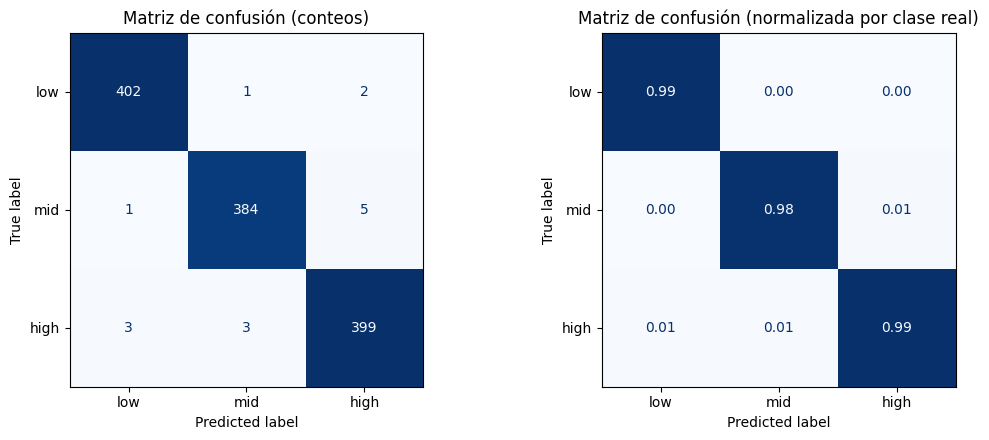

Recall por clase: {'low': np.float64(0.993), 'mid': np.float64(0.985), 'high': np.float64(0.985)}
Clase más fácil : low | más difícil: mid
Confusiones más frecuentes (real -> predicha, n):
  mid -> high: 5
  high -> low: 3
  high -> mid: 3


In [18]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Matriz de confusión (conteos)")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Matriz de confusión (normalizada por clase real)")
plt.tight_layout(); plt.show()

# Resumen automático para apoyar la interpretación
recall_pc = cm.diagonal() / cm.sum(axis=1)
print("Recall por clase:", dict(zip(CLASS_NAMES, recall_pc.round(3))))
print("Clase más fácil :", CLASS_NAMES[recall_pc.argmax()], "| más difícil:", CLASS_NAMES[recall_pc.argmin()])
off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(3) for j in range(3) if i != j]
off.sort(key=lambda t: -t[2])
print("Confusiones más frecuentes (real -> predicha, n):")
for a, b, n in off[:3]: print(f"  {a} -> {b}: {n}")

**Interpretación de métricas en TEST:**

- **Desempeño global:** accuracy 0.9875, loss 0.0411, F1 macro 0.987. Con 3 clases balanceadas el azar da ≈ 0.33, así que el modelo está muy por encima de esa referencia.
- **Clase más fácil / más difícil:** `low` tiene mayor recall (0.993) y `mid` el menor (0.985), aunque `high` queda igual con 0.985. La diferencia equivale a una o dos imágenes, por lo que no es concluyente. `mid` suele ser la más ambigua por ser intermedia entre `low` y `high`.
- **Confusiones más frecuentes:** mid → high (5 casos), high → low (3) y high → mid (3). Las confusiones mid↔high suman 8 y low↔high suman 5, mientras que low↔mid suman solo 2. Por lo tanto, el error no se concentra solo en clases adyacentes: hay errores entre los extremos, aunque son pocos (5 de 1.200).
- **Precision vs recall:** ninguna clase muestra un desbalance marcado (precision 0.983–0.990 y recall 0.985–0.993), así que el modelo no favorece sistemáticamente a ninguna clase.
- **Train vs Validation vs Test:** accuracy 0.9992 / 0.9875 / 0.9875 y loss 0.0026 / 0.0312 / 0.0411. Val ≈ test, así que la selección en validación generalizó bien y no hubo sobreajuste al conjunto de validación. La brecha train–test es pequeña.

## 8. Análisis visual de 10 imágenes de TEST

Se seleccionan **10 imágenes al azar** (semilla fija para reproducibilidad) y se muestran con la clase oficial, la predicción y las probabilidades P(low), P(mid), P(high).

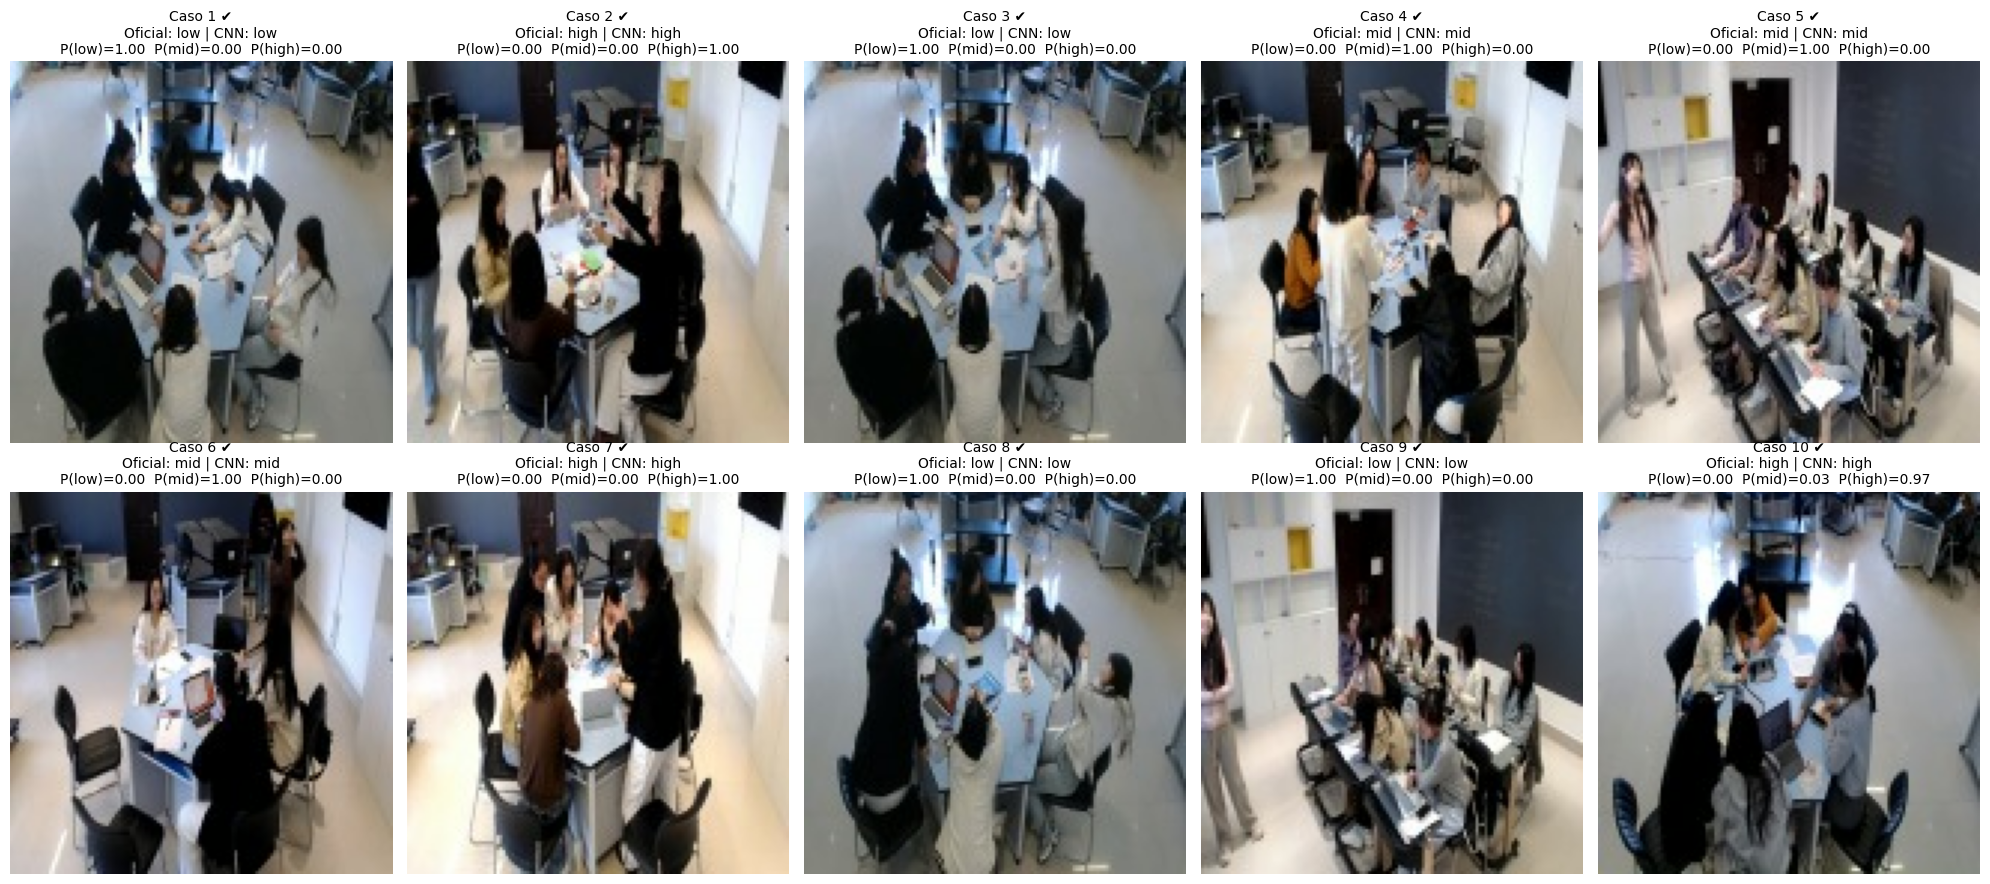

In [19]:
# Recuperar imágenes, clip_key y ruta de TEST en el MISMO orden usado para las predicciones
spec = {"image_raw": tf.io.FixedLenFeature([], tf.string), "label": tf.io.FixedLenFeature([], tf.int64),
        "clip_key": tf.io.FixedLenFeature([], tf.string), "image_relpath": tf.io.FixedLenFeature([], tf.string)}
test_images, test_clip, test_path = [], [], []
for rec in tf.data.TFRecordDataset(TEST_FILES):
    ex = tf.io.parse_single_example(rec, spec)
    test_images.append(tf.io.decode_jpeg(ex["image_raw"], channels=3).numpy())
    test_clip.append(ex["clip_key"].numpy().decode()); test_path.append(ex["image_relpath"].numpy().decode())
test_images = np.stack(test_images)
assert len(test_images) == len(y_true)
assert np.array_equal(np.array([int(tf.io.parse_single_example(r, spec)["label"]) for r in tf.data.TFRecordDataset(TEST_FILES).take(50)]), y_true[:50]), "Orden inconsistente"

rng = np.random.default_rng(SEED)
idx = rng.choice(len(y_true), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for k, (ax, i) in enumerate(zip(axes.ravel(), idx), start=1):
    ax.imshow(test_images[i]); ax.axis("off")
    ok = "✔" if y_pred[i] == y_true[i] else "✘"
    ax.set_title(f"Caso {k} {ok}\nOficial: {CLASS_NAMES[y_true[i]]} | CNN: {CLASS_NAMES[y_pred[i]]}\n"
                 f"P(low)={test_probs[i,0]:.2f}  P(mid)={test_probs[i,1]:.2f}  P(high)={test_probs[i,2]:.2f}", fontsize=10)
plt.tight_layout(); plt.show()

In [23]:
OBSERVACIONES = [
    ("Parcialmente observable", "Sí", "Grupo sentado en torno a la mesa con laptops, varios mirando hacia abajo; el nivel low es plausible pero un frame aislado no muestra la dinámica del clip."),
    ("Parcialmente observable", "Sí", "Se ven varias personas interactuando y gestos con las manos; coherente con high, aunque falta contexto temporal."),
    ("Parcialmente observable", "Sí", "Escena similar al caso 1: grupo concentrado en pantallas, poca interacción visible."),
    ("Parcialmente observable", "Sí", "Algunos miran al grupo y otros a sus equipos; mid es razonable por ser un nivel mixto."),
    ("Parcialmente observable", "Sí", "Una persona de pie y varios con laptops; el nivel mid es razonable, pero la postura de pie no basta para saber la participación."),
    ("Parcialmente observable", "Sí", "Pocas personas visibles en la mesa y una de pie al fondo; poca información visual."),
    ("Parcialmente observable", "Sí", "Varias personas con posturas activas hacia el centro de la mesa; coherente con high."),
    ("Parcialmente observable", "Sí", "Grupo agachado sobre laptops; coherente con low."),
    ("No claramente observable", "Sí", "Cámara lejana y personas pequeñas, con una persona de pie a un lado; no se distingue la mirada ni la interacción. La CNN pudo apoyarse en la escena o la disposición del grupo."),
    ("Parcialmente observable", "Sí", "Grupo cercano a la cámara con posturas orientadas al centro; coherente con high."),
]

## 9. Discusión

### Evidencia adicional (complementaria): ¿ayuda ver los 3 frames de un clip?
Cada clip aporta 3 imágenes. Como análisis *complementario* (no se usa para seleccionar nada), se promedian las probabilidades de los 3 frames del mismo clip y se compara con la predicción frame a frame. Esto ilustra cuánta información temporal se pierde al usar imágenes aisladas.

In [21]:
tmp = pd.DataFrame({"clip": test_clip, "y": y_true, "pred": y_pred})
tmp[["p0", "p1", "p2"]] = test_probs
g = tmp.groupby("clip").agg(y=("y", "first"), p0=("p0", "mean"), p1=("p1", "mean"), p2=("p2", "mean"), n=("y", "size"))
g["pred_clip"] = g[["p0", "p1", "p2"]].values.argmax(axis=1)
print("Clips en TEST:", len(g), "| frames por clip:", g["n"].unique())
print(f"Accuracy por IMAGEN: {(y_pred == y_true).mean():.3f}")
print(f"Accuracy por CLIP (promedio de 3 frames): {(g['pred_clip'] == g['y']).mean():.3f}")

# ¿Los 3 frames de un clip reciben la misma predicción?
consist = tmp.groupby("clip")["pred"].nunique()
print(f"Clips cuyos 3 frames reciben la misma predicción: {(consist == 1).mean():.1%}")

Clips en TEST: 400 | frames por clip: [3]
Accuracy por IMAGEN: 0.988
Accuracy por CLIP (promedio de 3 frames): 0.995
Clips cuyos 3 frames reciben la misma predicción: 97.2%


**Fortalezas y limitaciones de la arquitectura:** Fortalezas: BN + Dropout controlan el overfitting, los kernels 3×3 capturan patrones locales y GAP reduce parámetros (Exp. 4: 1.19 M frente a 4.29 M). Limitaciones: resolución 128×128 limita detalles finos (mirada, objetos pequeños), el modelo se entrenó desde cero con ~9.600 imágenes y no hay información temporal.

**Impacto de los hiperparámetros:** (i) Regularización: BN + Dropout (Exp. 2) bajó el accuracy de 0.9875 a 0.9583 y subió la val_loss de 0.031 a 0.313. (ii) Augmentation: fue lo más perjudicial (Exp. 3: 0.6317). (iii) Profundidad/GAP: el Exp. 4 con 4 bloques y GAP llegó a 0.9492 con menos parámetros. (iv) Learning rate y batch: el Exp. 4 usó LR 0.0005 y batch 32, con convergencia más lenta pero más estable que el Exp. 2.

**Comportamiento de las curvas:** El Exp. 1 converge en pocas épocas y se detiene por EarlyStopping en la 13. Los Exp. 2 y 4 muestran oscilaciones en val_accuracy al inicio y se estabilizan con ReduceLROnPlateau. El Exp. 3 se estanca en ~0.63, lo que indica subajuste.

**Train vs Validation vs Test:** accuracy 0.9992 / 0.9875 / 0.9875. Val ≈ test: la selección generalizó bien.

**Clases fáciles/difíciles y confusiones:** `low` es la más fácil (recall 0.993). Los errores se concentran entre mid↔high (8 casos), seguidos de low↔high (5) y low↔mid (2).

**Predicciones vs observación humana (10 imágenes):** 10/10 aciertos, pero en la mayoría la etiqueta no es claramente visible en un frame aislado.

**Evidencia adicional (3 frames por clip):** accuracy por imagen 0.988 y por clip 0.995; el 97.2% de los clips recibe la misma predicción en sus 3 frames. Promediar frames mejora ~0.7 puntos, lo que muestra que hay algo de información temporal que se pierde al usar imágenes aisladas.

**Pregunta central: ¿qué limitaciones tiene una CNN 2D con imágenes estáticas para inferir engagement?**

1. **Pérdida de la dimensión temporal.** El engagement se manifiesta como comportamiento a lo largo del clip y un frame es solo un instante. Promediar los 3 frames subió el accuracy de 0.988 a 0.995, y en el 97.2% de los clips los 3 frames reciben la misma predicción; el 2.8% restante (≈11 de 400 clips) muestra que frames de un mismo clip pueden dar señales distintas.
2. **Etiqueta no siempre observable en un frame.** En el análisis de las 10 imágenes, la mayoría quedó como "parcialmente observable", porque la etiqueta se asignó al clip completo y no a la imagen.
3. **Posible dependencia de indicios indirectos.** Las diferencias entre clases son sutiles (misma sala, cámara e iluminación), por lo que el modelo podría apoyarse en la agrupación de personas o en quién está de pie más que en la atención real. Esto no se comprobó; una técnica de explicabilidad (p. ej. Grad-CAM) permitiría verificarlo.
4. **Resolución limitada (128×128).** Mirada, uso de celulares o gestos finos no se distinguen.
5. **Contexto acotado.** Val ≈ test demuestra generalización a clips nuevos del mismo entorno, no a otras aulas, cámaras o actividades.

**Posibles mejoras futuras:** modelos temporales (CNN+LSTM, CNN 3D) que usen los 3 frames como secuencia; transfer learning con una red preentrenada; explicabilidad (Grad-CAM); mayor resolución; ablaciones que cambien un factor a la vez; y validación en otras aulas.

**Conclusiones**

1. Se diseñó una CNN 2D en TensorFlow/Keras y se compararon **4 experimentos** variando regularización, augmentation, profundidad, learning rate y batch size, usando **solo validation** para decidir.
2. El mejor modelo fue el **Experimento 1** (val_accuracy = 0.9875, val_loss = 0.0312). En **TEST** obtuvo accuracy 0.9875 y F1 macro 0.987, **consistente** con lo visto en validation, por lo que no hubo sobreajuste al conjunto de validación.
3. La clase más fácil fue **low** (recall 0.993) y la más difícil **mid** (recall 0.985, casi empatada con high); los errores principales fueron **mid → high (5 casos), high → low (3) y high → mid (3)**, con solo 15 errores en 1.200 imágenes.
4. Los experimentos mostraron que **la arquitectura base simple (Exp. 1) superó a las variantes con más regularización y augmentation**: BN + Dropout (Exp. 2) bajó el accuracy a 0.9583 y la augmentation (Exp. 3) lo hundió a 0.6317, mientras que la arquitectura más profunda con GAP (Exp. 4) alcanzó 0.9492 con 3.6 veces menos parámetros. Es decir, más regularización no implicó mejor desempeño en este problema.
5. El análisis visual evidenció que **en los 10 casos revisados el modelo acertó, pero la etiqueta oficial solo era parcialmente observable en la mayoría de los frames**, y que una imagen aislada no siempre contiene la información suficiente para representar el engagement del clip. Esto se refuerza con la evidencia por clip: promediar los 3 frames subió el accuracy de 0.988 a 0.995.
6. Limitación principal: la naturaleza temporal del engagement no es capturable por una CNN 2D sobre frames. Trabajo futuro: modelos temporales, transfer learning y explicabilidad.